# Estudio 06 · Ajuste de hiperparámetros de L + 5a + d3

Preregistro `HP_TUNING` (commit `b408371`; aprobado por Rosa tal cual, con el agregado del tope de 10 h y la
declaración del Niño en `02d7275`, antes de correr). La búsqueda (300 trials de TPE, objetivo = media del Brier
calibrado relativo a los heredados sobre 2009, 2012, 2013, 2014, 2018 y 2021) corrió aparte con
`code/phase_hp_tuning.py` y quedó guardada en `models/experimentos/mejora_modelo/ajuste_hp/optuna.db`. Aquí:
resumen de la búsqueda, las 5 mejores con 5 semillas y, si alguna mejora a los heredados, la comparación final con
L + 5a + d3 heredado (regla `SEASON_2026` + filtro de >= 16 de 24 celdas fuera de temporada).

In [1]:
import json
import sys

import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd

from denguekay.config.paths import MODELS, RESEARCH

STUDY = RESEARCH / "06_model_improvement"
sys.path.insert(0, str(STUDY / "code"))
import phase3_onsets as p3
import phase_2026 as p26
import phase_climate_matrix as cm
import phase_hp_tuning as ht
import preregistration as pr

pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_rows", 400)
OUT = MODELS / "experimentos" / "mejora_modelo" / "ajuste_hp"
FIG = STUDY / "docs" / "figuras"
METRICS = STUDY / "docs" / "metricas" / "ajuste_hp.json"
optuna.logging.set_verbosity(optuna.logging.WARNING)
st = optuna.load_study(study_name=ht.STUDY_NAME, storage=f"sqlite:///{(OUT / 'optuna.db').as_posix()}")
inp = p26.inputs_2026()
origins, _ = p26.add_climate(inp)
COLS = ht.study_columns()
reference = pd.read_csv(OUT / "referencia_heredados.csv")
len(st.trials)

C:\Users\Rosa\RufoEsEternoElRegreso\Denguekay\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


255

## 1 · Búsqueda: trials, tiempo, curva e importancia

In [2]:
rows = []
for t in st.trials:
    rows.append({"numero": t.number, "estado": t.state.name, "objetivo": t.value,
                 "es_base": bool(t.user_attrs.get("es_base", False)), "segundos": t.user_attrs.get("segundos"),
                 "logloss_media": t.user_attrs.get("logloss_media"), "inicio": t.datetime_start,
                 "fin": t.datetime_complete, **{f"param_{k}": v for k, v in t.params.items()}})
trials = pd.DataFrame(rows)
states = trials.estado.value_counts().to_dict()
wall = (trials.fin.max() - trials.inicio.min()).total_seconds()
search = {"trials_por_estado": states, "trials_completos": int(trials.estado.eq("COMPLETE").sum()),
          "trials_fallidos": int(trials.estado.eq("FAIL").sum()), "segundos_de_pared": wall,
          "segundos_suma_trials": float(trials.segundos.sum()), "segundos_mediana_trial": float(trials.segundos.median()),
          "alcanzo_tope_10h": bool(len(trials) < pr.HP_TUNING_N_TRIALS),
          "objetivo_trial_0": float(trials.loc[trials.es_base, "objetivo"].iloc[0]),
          "mejor_objetivo": float(trials.objetivo.min())}
search

{'trials_por_estado': {'COMPLETE': 255},
 'trials_completos': 255,
 'trials_fallidos': 0,
 'segundos_de_pared': 36067.430715,
 'segundos_suma_trials': 36017.72347090003,
 'segundos_mediana_trial': 148.00444260000222,
 'alcanzo_tope_10h': True,
 'objetivo_trial_0': 1.0000009666908456,
 'mejor_objetivo': 0.9609656192804061}

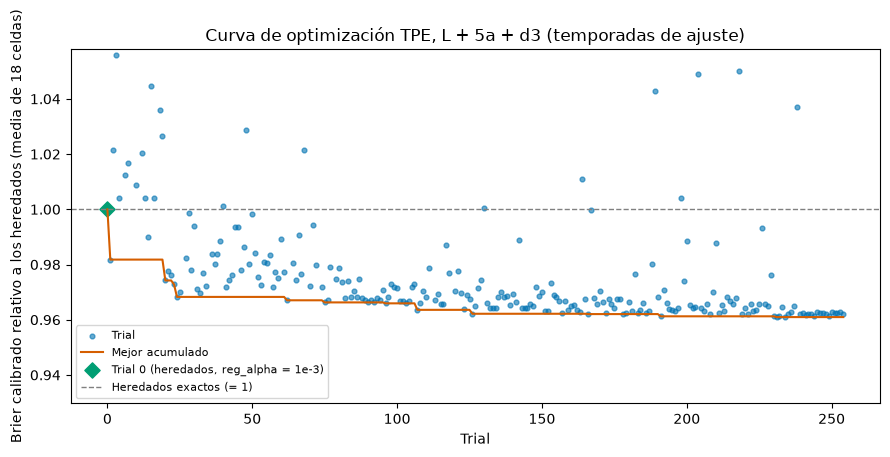

In [3]:
ok = trials[trials.estado.eq("COMPLETE")].sort_values("numero")
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.scatter(ok.numero, ok.objetivo, s=12, color="#0072B2", alpha=0.6, label="Trial")
ax.plot(ok.numero, ok.objetivo.cummin(), color="#D55E00", label="Mejor acumulado")
z = ok[ok.es_base]
ax.scatter(z.numero, z.objetivo, s=60, marker="D", color="#009E73", label="Trial 0 (heredados, reg_alpha = 1e-3)")
ax.axhline(1.0, color="grey", linestyle="--", linewidth=1, label="Heredados exactos (= 1)")
ax.set_ylim(top=min(float(ok.objetivo.quantile(0.95)), 1.5))
ax.set_xlabel("Trial")
ax.set_ylabel("Brier calibrado relativo a los heredados (media de 18 celdas)")
ax.set_title("Curva de optimización TPE, L + 5a + d3 (temporadas de ajuste)")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG / "ajuste_hp_curva.png", dpi=150)

n_estimators        0.483
learning_rate       0.145
reg_alpha           0.141
min_child_weight    0.058
colsample_bytree    0.045
max_depth           0.042
max_delta_step      0.040
subsample           0.036
gamma               0.007
reg_lambda          0.003
dtype: float64

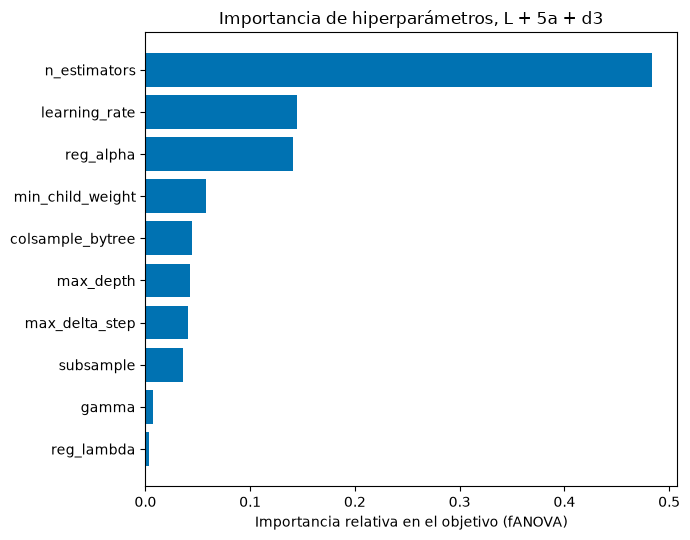

In [4]:
importance = optuna.importance.get_param_importances(st, evaluator=optuna.importance.FanovaImportanceEvaluator(seed=pr.HP_TUNING_TPE_SEED))
s = pd.Series(importance).sort_values()
fig, ax = plt.subplots(figsize=(7, 0.4 * len(s) + 1.5))
ax.barh(s.index, s.values, color="#0072B2")
ax.set_xlabel("Importancia relativa en el objetivo (fANOVA)")
ax.set_title("Importancia de hiperparámetros, L + 5a + d3")
fig.tight_layout()
fig.savefig(FIG / "ajuste_hp_importancia.png", dpi=150)
s.sort_values(ascending=False).round(3)

## 2 · Las 5 mejores con 5 semillas (bloques de ajuste)

In [5]:
best = ok[~ok.es_base & np.isfinite(ok.objetivo)].nsmallest(pr.HP_TUNING_TOP_K, "objetivo")
params_of = {int(n): st.trials[int(n)].params for n in best.numero}
top_path = OUT / "top5_semillas.csv"
if top_path.exists():
    top = pd.read_csv(top_path)
else:
    rows = []
    for n, params in params_of.items():
        for seed in pr.SEEDS:
            cells = ht.run_trial(inp["matrices"], origins, COLS, params, seed)
            rows.append({"trial": n, "semilla": seed, "objetivo": ht.relative_objective(cells, reference),
                         "logloss_media": float(cells.logloss.mean())})
    top = pd.DataFrame(rows)
    top.to_csv(top_path, index=False)
medians = top.groupby("trial").objetivo.median()
candidate_n = pr.hp_tuning_choose(medians.to_dict())
cand_median = float(medians[candidate_n])
top_table = top.groupby("trial").objetivo.agg(["median", "min", "max"]).join(best.set_index("numero").objetivo.rename("semilla_17_busqueda"))
print("candidata: trial", candidate_n, "| mediana del objetivo", round(cand_median, 4), "| mejora a los heredados:", cand_median < 1)
top_table.round(4)

candidata: trial 191 | mediana del objetivo 0.9617 | mejora a los heredados: True


,median,min,max,semilla_17_busqueda
trial,,,,
191,0.9617,0.9607,0.9625,0.9612
231,0.9621,0.9595,0.9633,0.9610
232,0.9625,0.9598,0.9632,0.9612
234,0.9619,0.9609,0.9628,0.9611
244,0.9619,0.9610,0.9632,0.9613


In [6]:
inh = ht.inherited()
cand_params = params_of[candidate_n]
pd.DataFrame({"heredados": pd.Series(inh), "candidata": pd.Series(cand_params)}).loc[list(pr.HP_TUNING_SPACE)]

,heredados,candidata
max_depth,3.00,8.000000
min_child_weight,5.00,1.347204
learning_rate,0.05,0.012202
n_estimators,160.00,1055.000000
subsample,0.80,0.637422
colsample_bytree,0.90,0.523118
reg_lambda,5.00,27.462611
reg_alpha,0.00,0.826357
gamma,0.00,0.010338
max_delta_step,0.70,1.583021


## 3 · Comparación final (solo si la candidata mejora a los heredados)

In [7]:
final = None
if cand_median < 1:
    hp = {**inh, **cand_params}
    path = OUT / "predicciones_candidata.csv.gz"
    cand = (p26.evaluate_saved(path, inp["serie"]) if path.exists()
            else p26.run_variant(inp, origins, COLS, hp))
    if not path.exists():
        pd.concat([p.assign(semilla=s) for s, p in cand["predicciones"].items()], ignore_index=True).to_csv(path, index=False)
    ref = p26.evaluate_saved(MODELS / "experimentos" / "mejora_modelo" / "matriz_clima" / "predicciones_d3.csv.gz", inp["serie"])
    outbreaks = p26.outbreak_weeks(inp["serie"])
    res = p26.compare_2026(cand, ref, outbreaks)
    lpath = OUT / "fuera_de_temporada_candidata.csv.gz"
    if lpath.exists():
        lpreds = p26.read_saved(lpath)
    else:
        lpreds = {s: cm.loso_predictions(inp, origins, COLS, hp, s) for s in pr.SEEDS}
        pd.concat([p.assign(semilla=s) for s, p in lpreds.items()], ignore_index=True).to_csv(lpath, index=False)
    lref = p26.read_saved(MODELS / "experimentos" / "mejora_modelo" / "matriz_clima" / "fuera_de_temporada_d3.csv.gz")
    loso_all = pd.concat({"candidata": p26.loso_metrics(lpreds, inp["serie"]), "d3": p26.loso_metrics(lref, inp["serie"])},
                         names=["variante"]).reset_index(level=0)
    better = cm.loso_better_cells(loso_all, "candidata", reference="d3")
    adopted = pr.adopt_hp_tuning(res["brier"], res["alerta"], res["conteo"], better, cand_median)
    cm_c, cm_r = p26.cell_metrics(cand, inp["serie"]), p26.cell_metrics(ref, inp["serie"])
    b = cm_c[["horizonte", "bloque", "brier"]].merge(cm_r[["horizonte", "bloque", "brier"]], on=["horizonte", "bloque"],
                                                     suffixes=("_candidata", "_heredados"))
    b["dif_pct"] = 100 * (b.brier_candidata / b.brier_heredados - 1)
    groups = {"decisivas": [pr.block_name(x) for x in pr.SEASON_2026_DECIDING],
              "nino": ["temporada_2017", "temporada_2026", "posterior_2026"]}
    groups["normales"] = [x for x in b.bloque.unique() if x not in groups["nino"]]
    groups["todas"] = list(b.bloque.unique())
    means = {g: {"celdas": int(b.bloque.isin(v).sum()), "dif_pct_media": float(b[b.bloque.isin(v)].dif_pct.mean())}
             for g, v in groups.items()}
    final = {"veredicto_brier": res["brier"], "veredicto_alerta": res["alerta"], "veredicto_conteo": res["conteo"],
             "gana_season_2026": bool(res["adopta"]), "celdas_loso_mejores": better, "adoptada": adopted,
             "brier_por_celda": b, "promedios": means, "metricas_candidata": cm_c}
    for k in ("veredicto_brier", "veredicto_alerta", "veredicto_conteo"):
        print(k, final[k].veredicto.tolist())
    print("gana SEASON_2026:", final["gana_season_2026"], "| celdas LOSO mejores:", better, "| adoptada:", adopted)
    display(b.pivot_table(index="bloque", columns="horizonte", values="dif_pct").round(2))
    display(pd.DataFrame(means).T.round(2))
else:
    print("Ninguna de las 5 mejores mejora a los heredados (mediana >= 1): se quedan los heredados sin comparación final.")

veredicto_brier ['gana', 'gana', 'empate']
veredicto_alerta ['empate', 'empate', 'empate']
veredicto_conteo ['empate', 'empate', 'empate']
gana SEASON_2026: True | celdas LOSO mejores: 24 | adoptada: True


horizonte,2,3,4
bloque,,,
posterior_2026,-2.06,0.21,-0.46
temporada_2010,-5.01,-4.37,-4.05
temporada_2015,-0.52,-1.30,-2.48
temporada_2016,-5.53,-4.19,-1.54
temporada_2017,-3.91,-1.69,-1.55
temporada_2022,-1.13,0.33,2.65
temporada_2023,-3.38,-2.34,-1.38
temporada_2024,-6.47,-5.56,-4.83
temporada_2026,-8.69,-5.50,-5.32


,celdas,dif_pct_media
decisivas,18.0,-2.99
nino,9.0,-3.22
normales,18.0,-2.84
todas,27.0,-2.97


## 4 · Cifras

In [8]:
def records(df):
    return json.loads(df.to_json(orient="records", date_format="iso", force_ascii=False))

out = {
    "preregistro": "HP_TUNING (b408371; agregado 02d7275)",
    "busqueda": search,
    "importancia_fanova": {k: float(v) for k, v in importance.items()},
    "trials": records(trials.drop(columns=["inicio", "fin"])),
    "top5_semillas": records(top),
    "candidata": {"trial": candidate_n, "mediana_objetivo": cand_median, "parametros": cand_params},
    "heredados": inh,
    "comparacion_final": None if final is None else {
        k: (records(v) if isinstance(v, pd.DataFrame) else v) for k, v in final.items()},
    "quedan": ("candidata" if final is not None and final["adoptada"] else "heredados"),
}
METRICS.write_text(json.dumps(out, ensure_ascii=False, indent=1, default=str), encoding="utf-8")
print(METRICS.name, out["quedan"])

ajuste_hp.json candidata
